# Checkpoint 5: Query-Based Detector (RT-DETR-L)

Fine-tunes COCO-pretrained RT-DETR-L on VisDrone and evaluates it with the shared COCO protocol
(sequence-held-out validation split, every 3rd frame, ignored regions treated as "don't care").

Sections:
1. Setup
2. Configuration
3. Data
4. Training (resumes automatically from the last saved epoch)
5. Training curves
6. Validation metrics
7. Kaggle submission

## 1. Setup

Set `RUNTIME` to `"colab"` (checkpoints go to Google Drive) or `"local"` (checkpoints go to `runs/`).
On Colab, upload `kaggle.json` to the session first so the dataset can be downloaded.

In [1]:
RUNTIME = "local"  # "colab" or "local"
REPO_URL = "https://github.com/rudkoLA/ai-hw-2-rudko-omelianchuk.git"

In [2]:
import os
import subprocess
import sys
from pathlib import Path

if RUNTIME == "colab":
    repo_dir = Path("/content/ai-hw-2-rudko-omelianchuk")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir)
    uploaded_key = Path("/content/kaggle.json")
    if uploaded_key.exists():
        kaggle_key = Path.home() / ".kaggle" / "kaggle.json"
        kaggle_key.parent.mkdir(parents=True, exist_ok=True)
        kaggle_key.write_bytes(uploaded_key.read_bytes())
        kaggle_key.chmod(0o600)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "pycocotools", "kaggle"], check=True)

print(f"Working directory: {Path.cwd()}")

Working directory: c:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk


In [3]:
import pandas as pd
from ultralytics import RTDETR

from src.rtdetr import build_rtdetr_cfg, make_rtdetr_trainer
from src.setup_utils import ensure_dataset, resolve_storage, setup_environment
from src.submission import submit_to_kaggle
from src.ultralytics_utils import (
    evaluate_run,
    plot_training_curves,
    predict_submission,
    train_or_resume,
    write_yolo_split,
)

env = setup_environment(seed=42, mount_gdrive=False)
dataset_dir, coco_train, coco_val, class_names = ensure_dataset()
storage = resolve_storage(RUNTIME, "cp5_rtdetr")

[Environment]: CUDA GPU (NVIDIA GeForce RTX 3070, 8.0 GB VRAM) -> Mixed Precision (AMP Enabled)
[Dataset]: Resolved dataset root at -> dataset
[Storage]: local -> C:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\runs\cp5_rtdetr


## 2. Configuration

All tunable parameters. Give every experiment its own `run_name`: an existing run with the same name
is resumed (or skipped if finished) instead of being retrained.
Any other Ultralytics `train()` argument can be added to `TRAIN_EXTRA`.

In [4]:
CFG = {
    "run_name": "check5",
    "weights": "rtdetr-l.pt",       # COCO-pretrained
    "frame_stride": 3,
    # Schedule
    "imgsz": 640,
    "epochs": 30,
    "batch": 8,
    "optimizer": "AdamW",
    "lr0": 1e-4,
    "backbone_lr_mult": 0.1,         # backbone LR = lr0 * backbone_lr_mult
    "weight_decay": 1e-4,
    "warmup_epochs": 1,
    "warmup_bias_lr": 0.0,
    # Queries and denoising
    "num_queries": 300,
    "num_denoising": 100,            # 0 disables denoising training
    # Hungarian matching costs and loss weights
    "matcher_cost": {"class": 2.0, "bbox": 5.0, "giou": 2.0},
    "loss_gain": {"class": 1.0, "bbox": 5.0, "giou": 2.0},
    # Misc
    "workers": 4,
    "seed": 42,
}

TRAIN_EXTRA = {}

## 3. Data

Writes Ultralytics image lists for every `frame_stride`-th frame of each sequence. The frame selection is
the same one used by `VisDroneDataset`, so all detectors are trained and evaluated on identical frames.

In [5]:
data_yaml, frames = write_yolo_split(
    dataset_dir,
    {"train": coco_train, "val": coco_val},
    out_dir=storage / "lists",
    class_names=class_names,
    stride=CFG["frame_stride"],
)
del coco_train  # large; only the selected frames are needed from here on

[train]: 8,090 frames (stride=3) -> C:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\runs\cp5_rtdetr\lists\train.txt
[val]: 951 frames (stride=3) -> C:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\runs\cp5_rtdetr\lists\val.txt


## 4. Training

Checkpoints (`last.pt` every epoch, `best.pt`) and `results.csv` are written to `storage/<run_name>`.
Re-running this cell after an interruption resumes from `last.pt`; a finished run is not retrained.

In [13]:
model_cfg = build_rtdetr_cfg("rtdetr-l.yaml", num_queries=CFG["num_queries"], num_denoising=CFG["num_denoising"])
Trainer = make_rtdetr_trainer(
    model_cfg,
    matcher_cost=CFG["matcher_cost"],
    loss_gain=CFG["loss_gain"],
    backbone_lr_mult=CFG["backbone_lr_mult"],
)
run_dir = storage / CFG["run_name"]

train_or_resume(
    RTDETR,
    CFG["weights"],
    Trainer,
    run_dir,
    train_args={
        "data": str(data_yaml),
        **{k: CFG[k] for k in [
            "imgsz", "epochs", "batch", "optimizer", "lr0", "weight_decay",
            "warmup_epochs", "warmup_bias_lr", "workers", "seed",
        ]},
        **TRAIN_EXTRA,
    },
    config={**CFG, "train_extra": TRAIN_EXTRA},
)

Run 'check5': resume
Ultralytics 8.4.208  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3070, 8191MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\runs\cp5_rtdetr\lists\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Users\Dog\Desktop\ai-hw-2-rudko-omel

c:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\.venv\Lib\site-packages\torch\autograd\graph.py:823: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:96.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      15/30      7.57G     0.7626     0.4482    0.08692        124        640: 100% ━━━━━━━━━━━━ 1012/1012 1.4it/s 12:280.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 60/60 2.1it/s 28.9s0.2ss
                   all        951      38206      0.552      0.438      0.441      0.233

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      16/30       7.1G     0.7863     0.4522    0.07355        604        640: 0% ──────────── 0/1012  0.6s

c:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\.venv\Lib\site-packages\torch\autograd\graph.py:823: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:96.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      16/30      7.21G     0.7619     0.4453    0.08626         44        640: 100% ━━━━━━━━━━━━ 1012/1012 1.5it/s 11:240.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 60/60 5.0it/s 12.1s0.2s
                   all        951      38206       0.54      0.434      0.441      0.234

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      17/30      7.12G     0.8364     0.4161    0.09561        647        640: 0% ──────────── 0/1012  0.5s

c:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\.venv\Lib\site-packages\torch\autograd\graph.py:823: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:96.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (23 outputs left out)

c:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\.venv\Lib\site-packages\torch\autograd\graph.py:823: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:96.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      29/30       7.3G     0.6005     0.4491    0.06058         51        640: 100% ━━━━━━━━━━━━ 1012/1012 2.2it/s 7:480.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 60/60 4.9it/s 12.3s0.2s
                   all        951      38206      0.563      0.441      0.439      0.231

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      30/30      6.76G     0.5333     0.4627    0.06388        239        640: 0% ──────────── 0/1012  0.6s

c:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\.venv\Lib\site-packages\torch\autograd\graph.py:823: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:96.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      30/30      6.85G     0.6009     0.4497    0.06004         96        640: 100% ━━━━━━━━━━━━ 1012/1012 2.6it/s 6:230.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 60/60 5.2it/s 11.6s0.2s
                   all        951      38206      0.566       0.44      0.439      0.231

16 epochs completed in 2.057 hours.
Optimizer stripped from C:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\runs\cp5_rtdetr\check5\weights\last.pt, 66.2MB
Optimizer stripped from C:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\runs\cp5_rtdetr\check5\weights\best.pt, 66.2MB

Validating C:\Users\Dog\Desktop\ai-hw-2-rudko-omelianchuk\runs\cp5_rtdetr\check5\weights\best.pt...
Ultralytics 8.4.208  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3070, 8191MiB)
rtdetr-l summary (fused): 315 layers, 32,000,180 parameters, 0 gradients, 105.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━

## 5. Training curves

Per-epoch validation mAP and losses logged by Ultralytics. These per-epoch metrics use Ultralytics' own
evaluator; the final numbers in Section 6 come from the shared COCO evaluation.

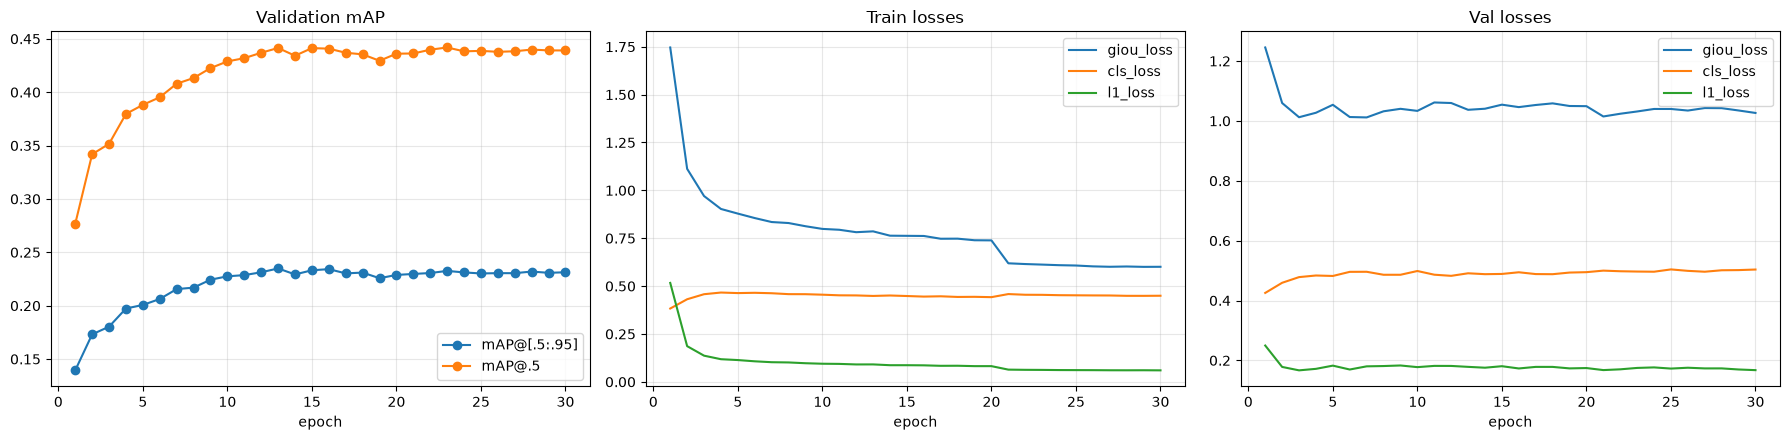

In [14]:
history = plot_training_curves(run_dir)

## 6. Validation metrics

`best.pt` is evaluated on the validation frames with `evaluate_coco_metrics` (up to 500 detections per image;
RT-DETR returns at most `num_queries` boxes and needs no NMS). Results are saved to `storage/<run_name>/metrics.json`.

In [15]:
best_model = RTDETR(str(run_dir / "weights" / "best.pt"))
metrics = evaluate_run(
    best_model,
    frames["val"],
    dataset_dir,
    imgsz=CFG["imgsz"],
    max_det=CFG["num_queries"],
    batch=CFG["batch"],
    run_dir=run_dir,
)
pd.Series(metrics, name=CFG["run_name"]).round(4).to_frame()

loading annotations into memory...
Done (t=0.26s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.76s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=40.20s).
Accumulating evaluation results...
DONE (t=1.62s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.449
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.221
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.094
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.217
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.417
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.134
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.327
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDe

,check5
mAP_50_95,0.2391
mAP_50,0.4489
mAP_75,0.2211
mAP_small,0.0942
mAP_medium,0.2173
mAP_large,0.4166
mAR,0.4318
mAR_small,0.2497
mAR_medium,0.4310
mAR_large,0.5800


## 7. Kaggle submission

Predicts all test frames with `best.pt` and writes `storage/<run_name>/submission.csv`
(boxes in original pixel coordinates, at most 500 detections per image, empty rows for frames without detections).

In [16]:
submission_path = run_dir / "submission.csv"
report = predict_submission(
    best_model,
    dataset_dir,
    submission_path,
    imgsz=CFG["imgsz"],
    max_det=CFG["num_queries"],
    batch=CFG["batch"],
)
report

{'is_valid': True,
 'errors': [],
 'rows': 3811,
 'expected_rows': 3811,
 'empty_rows': 0,
 'detections': 1143300,
 'size_MB': 35.62}

Set `SUBMIT = True` to upload the file (requires `~/.kaggle/kaggle.json`).

In [17]:
SUBMIT = True
SUBMISSION_MESSAGE = f"CP5 RT-DETR-L {CFG['run_name']}"
os.environ["KAGGLE_API_TOKEN"] = "KGAT_b939dc7b9ae093e004837dc162651189"

if SUBMIT:
    assert report["is_valid"], report["errors"]
    submit_to_kaggle(submission_path, SUBMISSION_MESSAGE)